#### Phase 5 - Random Forest

Loads what `src/train_rf.py` produced (`models/rf*.pkl`, `results/rf/`). Nothing is retrained here.

Same features, data and evaluation as the SVM, so the classifier is the only difference. A comparison model and fusion candidate.

In [1]:
import sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(str(Path.cwd().parent / "src"))
from config import CONFIG, resolve_path
from train_svm import evaluation_table

np.random.seed(CONFIG["seed"])

#### 1. Grid search and ground-truth-crop accuracy (`results/rf/rf_metrics.json`)


In [2]:
with open(resolve_path(CONFIG["paths"]["rf_metrics"])) as f:
    rf_metrics = json.load(f)
with open(resolve_path(CONFIG["paths"]["svm_metrics"])) as f:
    svm_metrics = json.load(f)

for source, v in rf_metrics["variants"].items():
    print(f"--- Random Forest / {source} ({v['role']}) - grid search, selection on validation split")
    print(pd.DataFrame(v["grid_search"]["log"]).to_string(index=False))
    print(f"best: {v['grid_search']['best_params']} "
          f"(val per-digit accuracy {v['grid_search']['best_val_per_digit_accuracy']:.4f})\n")

for name, m in [("Random Forest", rf_metrics), ("SVM", svm_metrics)]:
    ref = m["variants"]["digit_crops"]["evaluation"]["testing"]["ground_truth_digit_crops"]
    print(f"{name:14s} reference variant on ground-truth test digit crops: "
          f"per-digit {ref['per_digit_accuracy']:.4f}, full-sequence {ref['full_sequence_accuracy']:.4f}")

--- Random Forest / digit_crops (reference) - grid search, selection on validation split
 n_estimators  max_depth  val_per_digit_accuracy
          100       10.0                  0.9150
          100       20.0                  0.9230
          100        NaN                  0.9200
          300       10.0                  0.9175
          300       20.0                  0.9200
          300        NaN                  0.9210
          500       10.0                  0.9160
          500       20.0                  0.9220
          500        NaN                  0.9230
best: {'n_estimators': 100, 'max_depth': 20} (val per-digit accuracy 0.9230)

--- Random Forest / counter_strips (deployed) - grid search, selection on validation split
 n_estimators  max_depth  val_per_digit_accuracy
          100       10.0                  0.7385
          100       20.0                  0.7505
          100        NaN                  0.7555
          300       10.0                  0.7425
       

#### 2. RF vs. SVM, same features, same protocol

                                                  full-sequence             per-digit        
classifier                                        Random Forest     SVM Random Forest     SVM
trained on     evaluated on                                                                  
counter_strips detector crops, equal-width               0.3638  0.5038        0.7699  0.8218
               detector crops, projection-profile        0.1938  0.3137        0.6146  0.7054
               ground-truth counter strips               0.4050  0.5363        0.7923  0.8528
               ground-truth digit crops                  0.4700  0.5687        0.8257  0.8695
digit_crops    detector crops, equal-width               0.1263  0.1325        0.4939  0.4906
               detector crops, projection-profile        0.0938  0.1275        0.4178  0.4291
               ground-truth counter strips               0.1462  0.1613        0.4933  0.4973
               ground-truth digit crops                  0.7

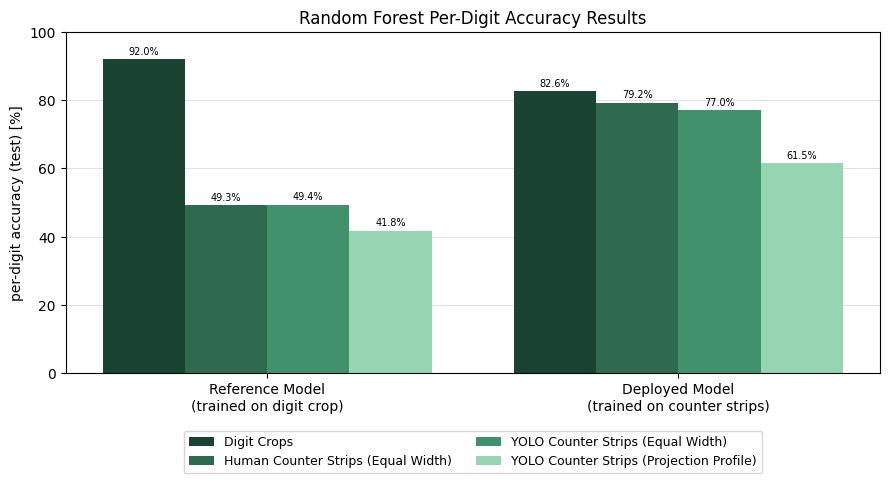

In [3]:
rf_table = pd.DataFrame(evaluation_table(rf_metrics)).assign(classifier="Random Forest")
svm_table = pd.DataFrame(evaluation_table(svm_metrics)).assign(classifier="SVM")
both = pd.concat([svm_table, rf_table])
print(both.pivot_table(index=["trained on", "evaluated on"], columns="classifier",
                       values=["per-digit", "full-sequence"]).round(4).to_string())

table = pd.DataFrame(evaluation_table(rf_metrics))
pivot = table.pivot(index="evaluated on", columns="trained on", values="per-digit")
row_order = ["ground-truth digit crops", "ground-truth counter strips",
             "detector crops, equal-width", "detector crops, projection-profile"]
pivot = pivot.reindex(row_order)

test_labels = ["Digit Crops", "Human Counter Strips (Equal Width)",
               "YOLO Counter Strips (Equal Width)", "YOLO Counter Strips (Projection Profile)"]
model_labels = ["Reference Model\n(trained on digit crop)", "Deployed Model\n(trained on counter strips)"]
model_cols = ["digit_crops", "counter_strips"]
colors = ["#1B4332", "#2D6A4F", "#40916C", "#95D5B2"]

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(model_cols))  # 2 model groups on the x-axis
n_tests = len(row_order)
width = 0.8 / n_tests

for i, (row_name, label, color) in enumerate(zip(row_order, test_labels, colors)):
    values = [pivot.loc[row_name, col] * 100 for col in model_cols]
    offset = (i - (n_tests - 1) / 2) * width
    bars = ax.bar(x + offset, values, width, label=label, color=color)
    ax.bar_label(bars, fmt="%.1f%%", fontsize=7, padding=2)

ax.set_axisbelow(True)
ax.grid(axis="y", color="lightgray", linewidth=0.7, alpha=0.7)
ax.set_xticks(x); ax.set_xticklabels(model_labels)
ax.set_ylim(0, 100); ax.set_ylabel("per-digit accuracy (test) [%]")
ax.set_title("Random Forest Per-Digit Accuracy Results")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, fontsize=9)
fig.tight_layout()
plt.show()

**Observation:** The SVM is stronger on every input, so it stays the strip-based model
the fusion combines with the CNN. The Random Forest shows the same pattern - a reference
variant that reads tight crops but not strips, and a deployed variant that recovers most
of the accuracy once trained on strips. The same train/inference mismatch appearing in two
structurally different classifiers points to the image representation, not the classifier.


#### 2b. SVM vs. RF on counter strips (deployed models)

The same deployed models, on counter strips only: cut from the ground-truth counter and from the YOLO
crop (as in the live pipeline).


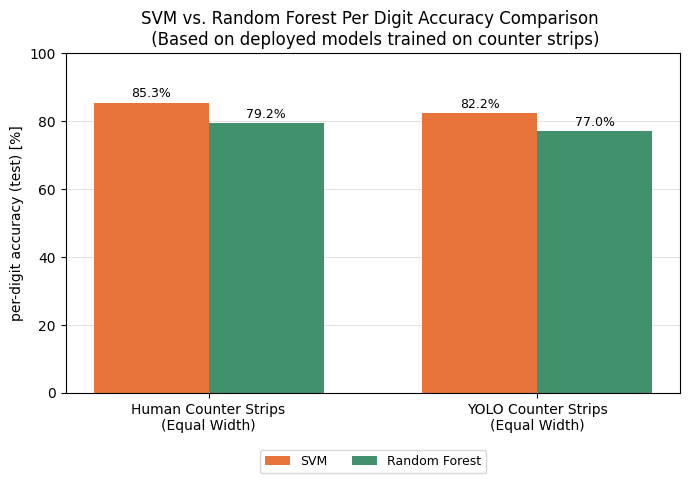

In [4]:
compare_inputs = ["ground-truth counter strips", "detector crops, equal-width"]
compare_labels = ["Human Counter Strips\n(Equal Width)", "YOLO Counter Strips\n(Equal Width)"]

svm_deploy = svm_table[svm_table["trained on"] == "counter_strips"].set_index("evaluated on")
rf_deploy = rf_table[rf_table["trained on"] == "counter_strips"].set_index("evaluated on")

fig, ax = plt.subplots(figsize=(7, 5))
x = np.arange(len(compare_inputs))
width = 0.35

for off, (name, t, col) in enumerate([("SVM", svm_deploy, "#E8743B"),
                                       ("Random Forest", rf_deploy, "#40916C")]):
    values = [t.loc[inp, "per-digit"] * 100 for inp in compare_inputs]
    bars = ax.bar(x + (off - 0.5) * width, values, width, label=name, color=col)
    ax.bar_label(bars, fmt="%.1f%%", fontsize=9, padding=2)

ax.set_axisbelow(True)
ax.grid(axis="y", color="lightgray", linewidth=0.7, alpha=0.7)
ax.set_xticks(x); ax.set_xticklabels(compare_labels)
ax.set_ylim(0, 100); ax.set_ylabel("per-digit accuracy (test) [%]")
ax.set_title("SVM vs. Random Forest Per Digit Accuracy Comparison \n (Based on deployed models trained on counter strips)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, fontsize=9)
fig.tight_layout()
plt.show()